# Level-set cutting with `cut_level_set` and `cut_quadrature`

`cut_level_set(mesh, level_sets)` returns the part of a mesh that one or several level sets select: the pieces of the cells they cross, on one side of them or on their zero sets, and the cells wholly inside. `cut_quadrature` returns quadrature rules on that part, the cut-cell quadrature of unfitted finite elements. Both run [CutCells](https://github.com/sclaus2/CutCells) (MIT), an optional dependency of the C++ core. See `doc/cut.md`.

In [1]:
import os
import tempfile

import numpy as np
import matplotlib.pyplot as plt

import meshioplusplus as mp

try:
    import pyvista as pv
    pv.OFF_SCREEN = True
except ImportError:  # pragma: no cover
    pv = None

WORK = tempfile.mkdtemp()
print('CutCells in this build:', mp.cut_has_cutcells())
R = 0.3


def ball(mesh, centre=(0.5, 0.5, 0.5), radius=R):
    """The signed distance to a sphere, as point data `ball`."""
    mesh.point_data['ball'] = np.linalg.norm(np.asarray(mesh.points) - centre, axis=1) - radius
    return mesh


def render(panels, title, size=(1500, 520)):
    """PyVista renders of (mesh, scalar or None, subtitle) panels, embedded
    through matplotlib; a matplotlib point scatter when GL is unavailable."""
    try:
        if pv is None:
            raise RuntimeError('no pyvista')
        pl = pv.Plotter(off_screen=True, shape=(1, len(panels)), window_size=size)
        for i, (mesh, scalar, sub) in enumerate(panels):
            pl.subplot(0, i)
            path = os.path.join(WORK, f'view{i}.vtu')
            mp.write(path, mesh)
            grid = pv.read(path)
            if scalar is not None and scalar in grid.array_names:
                pl.add_mesh(grid, scalars=scalar, cmap='viridis', show_edges=True,
                            edge_color='#1f4e79', line_width=0.3, scalar_bar_args={'title': scalar})
            else:
                pl.add_mesh(grid, color='#90caf9', show_edges=True, edge_color='#1f4e79', line_width=0.3)
            pl.add_text(sub, font_size=10)
            pl.camera_position = [(2.4, -1.6, 2.0), (0.5, 0.5, 0.5), (0, 0, 1)]
        img = pl.screenshot(return_img=True)
        pl.close()
        plt.figure(figsize=(15, 5.2))
        plt.imshow(img)
        plt.axis('off')
        plt.title(title)
        plt.tight_layout()
        plt.show()
    except Exception as exc:  # head-less GL fallback
        print('PyVista render skipped:', exc)
        fig = plt.figure(figsize=(15, 4.5))
        for i, (mesh, scalar, sub) in enumerate(panels):
            ax = fig.add_subplot(1, len(panels), i + 1, projection='3d')
            p = np.asarray(mesh.points)
            ax.scatter(p[:, 0], p[:, 1], p[:, 2], s=1, c=p[:, 2], cmap='viridis')
            ax.set_title(sub)
        fig.suptitle(title)
        plt.tight_layout()
        plt.show()

CutCells in this build: True


## A box of hexahedra cut by a sphere

The unit box as 12 x 12 x 12 hexahedra, and the signed distance to a sphere of radius 0.3 as point data. `"ball < 0"` keeps the pieces inside (hexahedra, wedges, pyramids and tetrahedra from the lookup tables, and the whole hexahedra the sphere holds), `"ball > 0"` the rest, `"ball = 0"` the interface. `cut:cut` tells the pieces of cut cells from whole cells.

inside:  1192 cells (224 of 1728 cut), volume 0.108760 (sphere 0.113097)
outside: volume 0.891240, the two sum to 1.000000000000
interface: 1020 faces, area 1.108261 (sphere 1.130973)
inside cell types: ['hexahedron', 'tetra', 'wedge']


/tmp/ipykernel_16924/3064780074.py:2: RuntimeWarning: meshio++: cut: the point and side regions 'xmax', 'xmin', 'ymax', 'ymin', 'zmax', 'zmin' are not carried to the pieces
  inside, ri = mp.cut_level_set(box, 'ball', return_report=True)
meshio warning [cut.cpp:959] meshio++: cut: the point and side regions 'xmax', 'xmin', 'ymax', 'ymin', 'zmax', 'zmin' are not carried to the pieces
meshio warning [cut.cpp:959] meshio++: cut: the point and side regions 'xmax', 'xmin', 'ymax', 'ymin', 'zmax', 'zmin' are not carried to the pieces
/tmp/ipykernel_16924/3064780074.py:3: RuntimeWarning: meshio++: cut: the point and side regions 'xmax', 'xmin', 'ymax', 'ymin', 'zmax', 'zmin' are not carried to the pieces
  outside, ro = mp.cut_level_set(box, 'ball', selection='ball > 0', return_report=True)
meshio warning [cut.cpp:959] meshio++: cut: the point and side regions 'xmax', 'xmin', 'ymax', 'ymin', 'zmax', 'zmin' are not carried to the pieces
/tmp/ipykernel_16924/3064780074.py:4: RuntimeWarning: mes

2026-11-03 22:22:57.232 (  15.268s) [    7F65CE19A080]vtkXOpenGLRenderWindow.:1452  WARN| bad X server connection. DISPLAY=


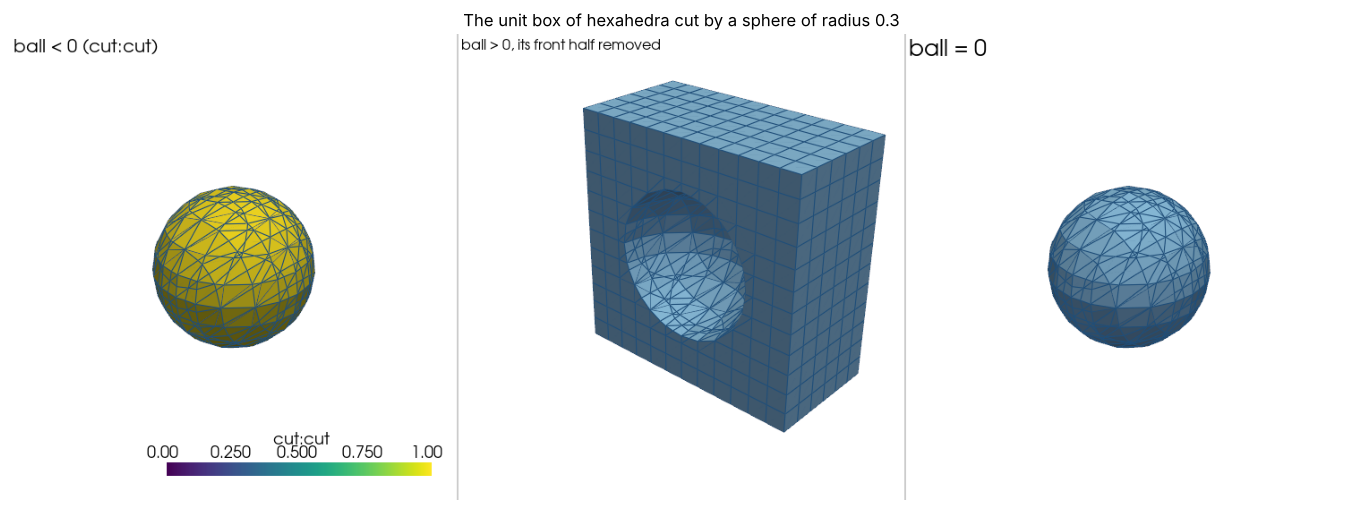

In [2]:
box = ball(mp.box((12, 12, 12)))
inside, ri = mp.cut_level_set(box, 'ball', return_report=True)
outside, ro = mp.cut_level_set(box, 'ball', selection='ball > 0', return_report=True)
skin, rs = mp.cut_level_set(box, 'ball', selection='ball = 0', return_report=True)
exact = 4 / 3 * np.pi * R**3
print(f'inside:  {ri["num_pieces"]} cells ({ri["num_cut_cells"]} of {ri["num_cells"]} cut), volume {ri["measure"]:.6f} (sphere {exact:.6f})')
print(f'outside: volume {ro["measure"]:.6f}, the two sum to {ri["measure"] + ro["measure"]:.12f}')
print(f'interface: {rs["num_pieces"]} faces, area {rs["measure"]:.6f} (sphere {4 * np.pi * R**2:.6f})')
print('inside cell types:', sorted({c.type for c in inside.cells}))
half = mp.cut_level_set(outside, planes=[((0.5, 0.5, 0.5), (0, -1, 0))])
render([(inside, 'cut:cut', 'ball < 0 (cut:cut)'),
        (half, None, 'ball > 0, its front half removed'),
        (skin, None, 'ball = 0')],
       'The unit box of hexahedra cut by a sphere of radius 0.3')

## Two level sets: a sharp edge

Level sets combine by `and` and `or`. The sphere cut by the plane `z = 0.6` gives a cap with a sharp circular edge where the two zero sets meet; the interface `"ball = 0 and plane0 < 0"` is the spherical part alone.

/tmp/ipykernel_16924/2987511417.py:2: RuntimeWarning: meshio++: cut: the point and side regions 'xmax', 'xmin', 'ymax', 'ymin', 'zmax', 'zmin' are not carried to the pieces
  cap, rc = mp.cut_level_set(box, 'ball', planes=plane, selection='ball < 0 and plane0 > 0', return_report=True)
meshio warning [cut.cpp:959] meshio++: cut: the point and side regions 'xmax', 'xmin', 'ymax', 'ymin', 'zmax', 'zmin' are not carried to the pieces
/tmp/ipykernel_16924/2987511417.py:3: RuntimeWarning: meshio++: cut: the point and side regions 'xmax', 'xmin', 'ymax', 'ymin', 'zmax', 'zmin' are not carried to the pieces
  dome = mp.cut_level_set(box, 'ball', planes=plane, selection='ball = 0 and plane0 > 0')
meshio warning [cut.cpp:959] meshio++: cut: the point and side regions 'xmax', 'xmin', 'ymax', 'ymin', 'zmax', 'zmin' are not carried to the pieces
/tmp/ipykernel_16924/2987511417.py:4: RuntimeWarning: meshio++: cut: the point and side regions 'xmax', 'xmin', 'ymax', 'ymin', 'zmax', 'zmin' are not carr

cap volume 0.027858 (exact 0.029322)


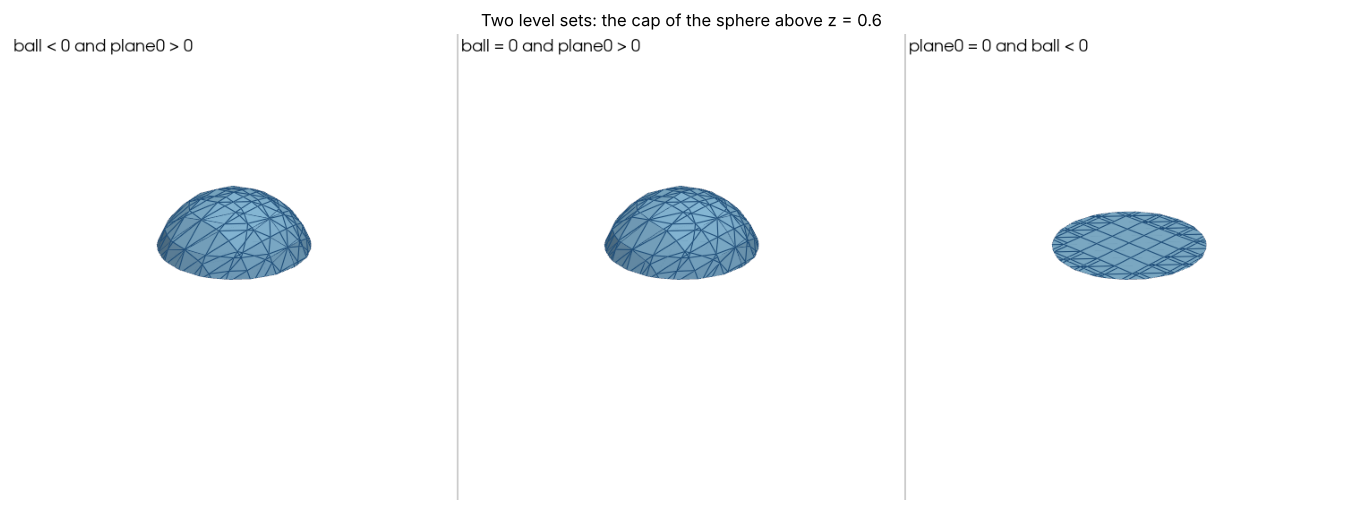

In [3]:
plane = [((0.0, 0.0, 0.6), (0.0, 0.0, 1.0))]
cap, rc = mp.cut_level_set(box, 'ball', planes=plane, selection='ball < 0 and plane0 > 0', return_report=True)
dome = mp.cut_level_set(box, 'ball', planes=plane, selection='ball = 0 and plane0 > 0')
flat = mp.cut_level_set(box, 'ball', planes=plane, selection='plane0 = 0 and ball < 0')
h = R - 0.1
print(f'cap volume {rc["measure"]:.6f} (exact {np.pi * h**2 * (3 * R - h) / 3:.6f})')
render([(cap, None, 'ball < 0 and plane0 > 0'), (dome, None, 'ball = 0 and plane0 > 0'),
        (flat, None, 'plane0 = 0 and ball < 0')],
       'Two level sets: the cap of the sphere above z = 0.6')

## Cut-cell quadrature

`cut_quadrature` writes one vertex per quadrature point at its physical position, with its weight, its coordinates in the parent cell's reference element and its parent cell. Summed, the weights are the part's measure; a degree-`k` rule integrates polynomials of degree `k` exactly on straight pieces. Here, a degree-3 rule on the sphere's interface integrates `z^2`.

8064 points in 224 rules; area 1.108261
integral of (z - 0.5)^2 over the interface: 0.032396 (sphere 0.033929)


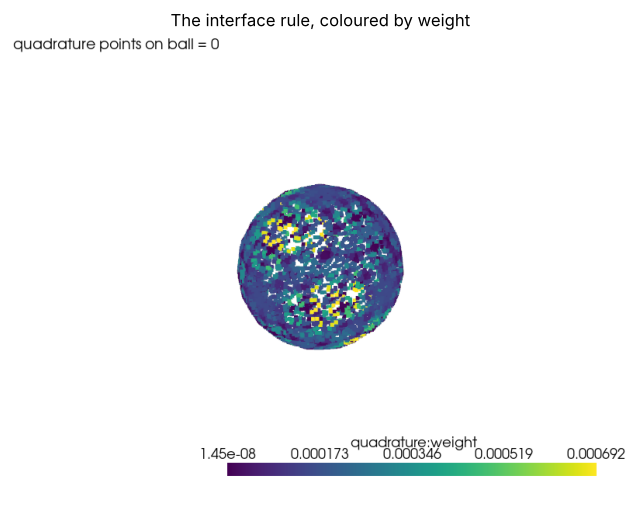

In [4]:
pts, rq = mp.cut_quadrature(box, 'ball', selection='ball = 0', order=3, return_report=True)
w = pts.point_data['quadrature:weight']
z = np.asarray(pts.points)[:, 2] - 0.5
print(f'{rq["num_points"]} points in {rq["num_rules"]} rules; area {rq["sum_weights"]:.6f}')
print(f'integral of (z - 0.5)^2 over the interface: {w @ z**2:.6f} (sphere {4 * np.pi * R**4 / 3:.6f})')
render([(pts, 'quadrature:weight', 'quadrature points on ball = 0')],
       'The interface rule, coloured by weight', size=(800, 600))

## Linear and quadratic level sets

On `tetra10` cells the level set is quadratic (its values at all ten nodes), and the `quadrays` backend integrates the curved interface to high order. The sphere's volume converges at second order with a linear level set on tetrahedra; the quadratic one on the same meshes is far closer.

h = 1/ 4: linear error 4.15e-02, quadratic (quadrays) 1.13e-04
h = 1/ 8: linear error 9.96e-03, quadratic (quadrays) 3.64e-05


h = 1/16: linear error 2.43e-03, quadratic (quadrays) 7.45e-07


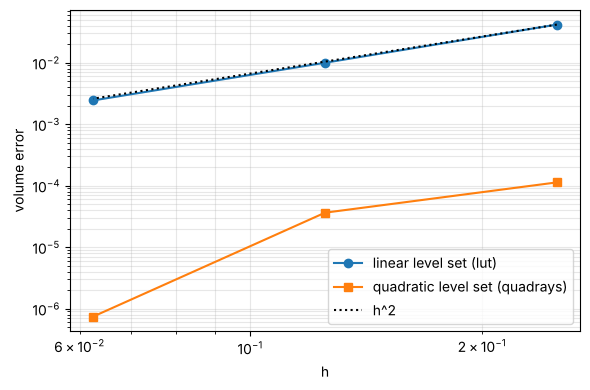

In [5]:
rows = []
for n in (4, 8, 16):
    lin = ball(mp.box((n, n, n), cell_type='tetra'))
    quad = ball(mp.box((n, n, n), cell_type='tetra', order=2))
    e1 = abs(mp.cut_quadrature(lin, 'ball', return_report=True)[1]['sum_weights'] - exact)
    _, r2 = mp.cut_quadrature(quad, 'ball', order=4, return_report=True)
    rows.append((1 / n, e1, abs(r2['sum_weights'] - exact)))
    print(f'h = 1/{n:2d}: linear error {e1:.2e}, quadratic ({r2["backend"]}) {rows[-1][2]:.2e}')
hs, e1s, e2s = map(np.array, zip(*rows))
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(hs, e1s, 'o-', label='linear level set (lut)')
ax.loglog(hs, e2s, 's-', label='quadratic level set (quadrays)')
ax.loglog(hs, e1s[0] * (hs / hs[0]) ** 2, 'k:', label='h^2')
ax.set_xlabel('h'); ax.set_ylabel('volume error'); ax.legend(); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## The other surfaces

The cut is the `CutLevelSet` pipeline step, the `cut` and `cut-quadrature` verbs of both CLIs, an MCP tool each, and on every binding (C, Fortran, Julia, R; WebAssembly binds it but does not link CutCells yet). Without CutCells every one of them refuses by name, pointing at `MESHIOPLUSPLUS_WITH_CUTCELLS`.

In [6]:
out, rep = mp.apply_operations(box, [{'Op': 'CutLevelSet', 'LevelSets': ['ball'], 'Selection': 'ball = 0'}])
print(rep['steps'][0])
print('meshioplusplus cut box.vtu skin.vtu --level-set ball --selection "ball = 0" --json')
print('meshioplusplus cut-quadrature box.vtu points.vtu --plane 0.3,0,0,1,0,0 --order 3')

{'op': 'CutLevelSet', 'NumCells': 1728.0, 'NumCutCells': 224.0, 'NumUncutCells': 0.0, 'NumPieces': 1020.0, 'Dimension': 2.0, 'Measure': 1.1082611014567492}
meshioplusplus cut box.vtu skin.vtu --level-set ball --selection "ball = 0" --json
meshioplusplus cut-quadrature box.vtu points.vtu --plane 0.3,0,0,1,0,0 --order 3


meshio warning [cut.cpp:959] meshio++: cut: the point and side regions 'xmax', 'xmin', 'ymax', 'ymin', 'zmax', 'zmin' are not carried to the pieces
